# Master — SLIKE kičma + nove lezije



## Ćelija 0 — priprema

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q nnunetv2 nibabel

import os, glob, shutil, subprocess, tarfile
import numpy as np, nibabel as nib
from scipy.ndimage import label
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import nnunetv2, torch

KICMA = '/content/drive/MyDrive/Master/kicma'
MOZAK = '/content/drive/MyDrive/Master/mozak'
SL_K = f'{KICMA}/rezultati/slike_kicma';       os.makedirs(SL_K, exist_ok=True)
SL_N = f'{MOZAK}/rezultati/slike_nove_lezije'; os.makedirs(SL_N, exist_ok=True)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('uredjaj:', DEV)

STRUKT = np.ones((3, 3, 3), int)
def ucitaj(p): return np.asarray(nib.load(p).dataobj)
def dice(pred, gt):
    p = pred > 0; t = gt > 0
    if p.sum() + t.sum() == 0: return float('nan')
    return float(2 * (p & t).sum() / (p.sum() + t.sum()))
def broj_lezija(m): return label(m > 0, STRUKT)[1]

CM = ListedColormap([(0, 0, 0, 0), (1, 0.9, 0, 0.9), (0, 0.9, 0, 0.9), (1, 0, 0, 0.9)])
def normiraj(f):
    lo, hi = np.percentile(f, [1, 99.5])
    return np.clip((f - lo) / (hi - lo + 1e-6), 0, 1)
def overlay2d(gt2d, pr2d):
    ov = np.zeros(gt2d.shape, int)
    ov[gt2d & pr2d] = 1; ov[gt2d & ~pr2d] = 2; ov[~gt2d & pr2d] = 3
    return ov
print('spremno')


Mounted at /content/drive
uredjaj: cuda
spremno


## Ćelija 1 — KIČMA: najbolji / srednji / najgori

raspakivam (nekoliko min)...


/tmp/ipykernel_550/308648743.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tar_path) as t: t.extractall('/content/multispine')


pacijenata: 20


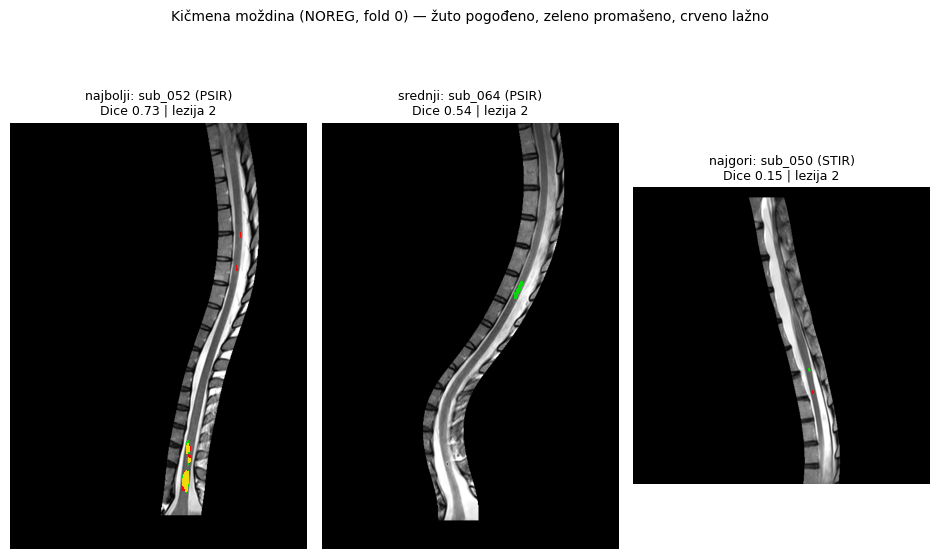

sacuvano u /content/drive/MyDrive/Master/kicma/rezultati/slike_kicma


In [ ]:

tar_path = f'{KICMA}/podaci_sirovi/MS_MultiSpine_dataset.tar.gz'
if not os.path.exists('/content/multispine'):
    print('raspakivam (nekoliko min)...')
    with tarfile.open(tar_path) as t: t.extractall('/content/multispine')
der = glob.glob('/content/multispine/**/derivatives', recursive=True)
PAR = f'{der[0]}/preprocessedAndRegistered'

def svi_nii(folder): return sorted(glob.glob(f'{folder}/**/*.nii*', recursive=True))
def nadji(folder, *k, ne=()):
    for x in k:
        for f in svi_nii(folder):
            n = os.path.basename(f).lower()
            if x in n and not any(y in n for y in ne): return f
    return None
def fajlovi(sub_dir):
    maske = ('lesion', 'mask', 'seg', 'label')
    t2 = nadji(sub_dir, 't2', ne=maske)
    mask = nadji(sub_dir, 'lesionmask', 'lesion', 'mask')
    extra, seq = None, None
    for s in ['stir', 'psir', 'mp2rage', 'unit1']:
        f = nadji(sub_dir, s, ne=maske)
        if f: extra, seq = f, ('MP2RAGE' if s == 'unit1' else s.upper()); break
    return dict(t2=t2, mask=mask, extra=extra, seq=seq)

SUBS = sorted(s for s in os.listdir(PAR) if s.startswith('sub-'))
mapa = {s.replace('-', '_'): s for s in SUBS}

VDIR = f'{KICMA}/modeli/nnUNet_results/Dataset013_SpineNOREG/nnUNetTrainer_100epochs_save10def__nnUNetPlans__3d_fullres/fold_0/validation'
assert os.path.isdir(VDIR), 'nema NOREG validation foldera na Drive-u'

def presek_kicma(vol, gt, pr, zooms):
    osa = int(np.argmin(vol.shape))                       # najtanja osa = pravac preseka (sagitalno)
    ost = tuple(i for i in range(3) if i != osa)
    i = int(np.argmax(gt.sum(axis=ost))) if gt.any() else int(np.argmax((pr > 0).sum(axis=ost)))
    uz = lambda a: np.rot90(np.take(a, i, axis=osa))
    rem = [z for k, z in enumerate(zooms) if k != osa]
    return uz(vol), uz(gt), uz(pr), rem[1] / rem[0]

REDOVI = []
for f in sorted(os.listdir(VDIR)):
    if not f.endswith('.nii.gz'): continue
    cid = f.replace('.nii.gz', '')
    if cid not in mapa: continue
    a = fajlovi(f'{PAR}/{mapa[cid]}')
    gt = ucitaj(a['mask']) > 0
    pr = ucitaj(f'{VDIR}/{f}') > 0
    REDOVI.append(dict(cid=cid, t2=a['t2'], seq=a['seq'], gt=a['mask'], pred=f'{VDIR}/{f}',
                       Dice=dice(pr, gt), n_gt=broj_lezija(gt), n_pred=broj_lezija(pr)))
print('pacijenata:', len(REDOVI))

def crtaj_k(ax, r):
    vol = ucitaj(r['t2']).astype(float); gt = ucitaj(r['gt']) > 0; pr = ucitaj(r['pred']) > 0
    zooms = nib.load(r['t2']).header.get_zooms()[:3]
    v2, g2, p2, asp = presek_kicma(vol, gt, pr, zooms)
    ov = overlay2d(g2, p2)
    ax.imshow(normiraj(v2), cmap='gray', aspect=asp)
    ax.imshow(np.ma.masked_where(ov == 0, ov), cmap=CM, vmin=0, vmax=3, interpolation='nearest', aspect=asp)
    ax.axis('off')

# slika za svakog pacijenta
for r in REDOVI:
    fig, ax = plt.subplots(figsize=(3.2, 6)); crtaj_k(ax, r)
    ax.set_title(f"{r['cid']} ({r['seq']})\nDice {r['Dice']:.2f} | lezija {r['n_gt']}", fontsize=8)
    fig.savefig(f"{SL_K}/{(0 if r['Dice'] != r['Dice'] else r['Dice']):.3f}_{r['cid']}.png", dpi=130, bbox_inches='tight')
    plt.close(fig)

# pregled: najbolji / srednji / najgori medju pacijentima SA lezijama
sa = sorted([r for r in REDOVI if r['n_gt'] > 0 and r['Dice'] == r['Dice']], key=lambda r: r['Dice'])
fig, axs = plt.subplots(1, 3, figsize=(9.5, 6.5))
for j, (ime, r) in enumerate([('najbolji', sa[-1]), ('srednji', sa[len(sa) // 2]), ('najgori', sa[0])]):
    crtaj_k(axs[j], r)
    axs[j].set_title(f"{ime}: {r['cid']} ({r['seq']})\nDice {r['Dice']:.2f} | lezija {r['n_gt']}", fontsize=9)
fig.suptitle('Kičmena moždina (NOREG, fold 0) — žuto pogođeno, zeleno promašeno, crveno lažno', fontsize=10)
plt.tight_layout(); fig.savefig(f'{SL_K}/PREGLED_kicma_najbolji_srednji_najgori.png', dpi=140); plt.show()
print('sacuvano u', SL_K)


## Ćelija 2 — NOVE LEZIJE: raniji / noviji / označene nove

predikcija 3 pacijenata na cuda (GPU: par minuta; CPU: ~10-15 min po pacijentu)...


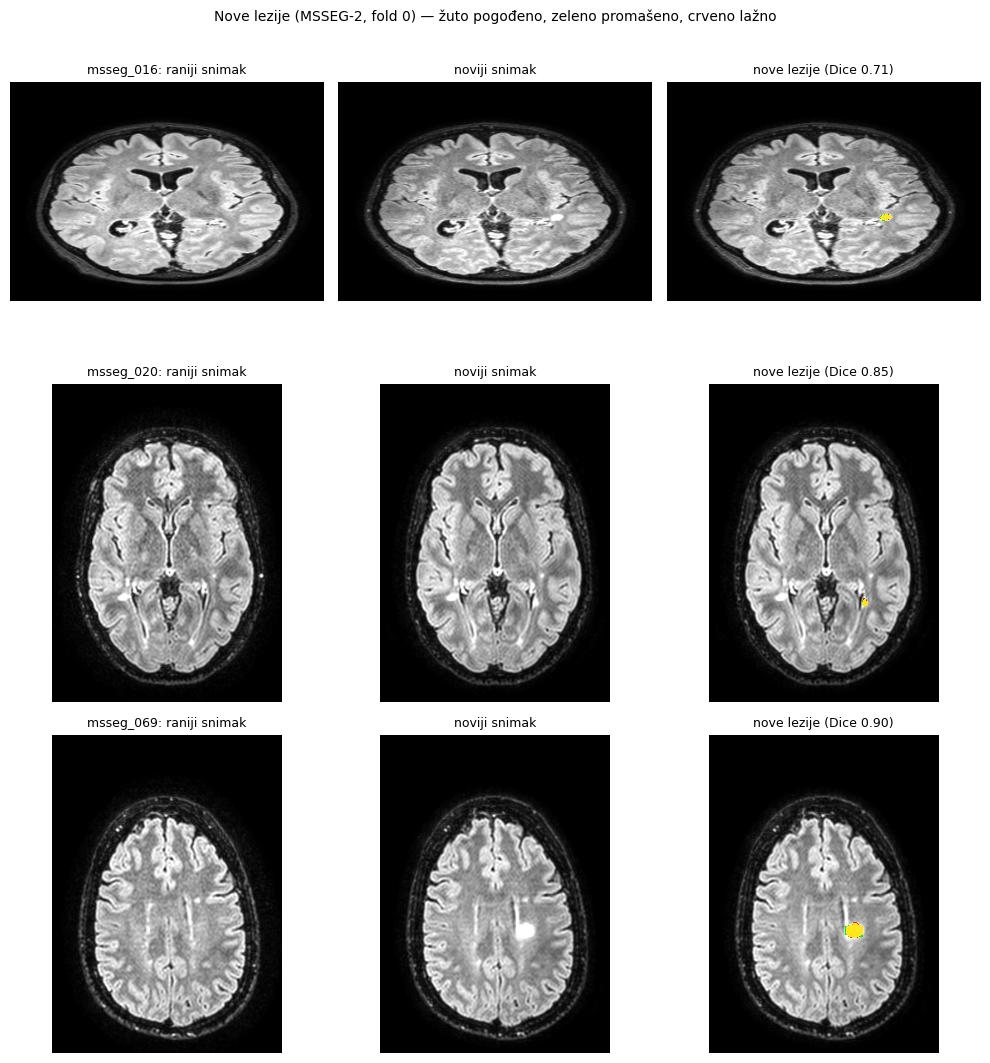

sacuvano u /content/drive/MyDrive/Master/mozak/rezultati/slike_nove_lezije


In [ ]:
PACIJENTI = ['016', '020', '069']
TR_NAME = 'nnUNetTrainer_100epochs_save10'
vdir = os.path.join(os.path.dirname(nnunetv2.__file__), 'training', 'nnUNetTrainer', 'variants', 'training_length')
with open(os.path.join(vdir, f'{TR_NAME}.py'), 'w') as fh:
    fh.write('''import torch
from nnunetv2.training.nnUNetTrainer.variants.training_length.nnUNetTrainer_Xepochs import nnUNetTrainer_100epochs
class nnUNetTrainer_100epochs_save10(nnUNetTrainer_100epochs):
    def __init__(self, plans, configuration, fold, dataset_json, device=torch.device('cuda')):
        super().__init__(plans, configuration, fold, dataset_json, device)
        self.save_every = 10
        self.initial_lr = 1e-3
        self.oversample_foreground_percent = 0.5
''')
os.environ['nnUNet_raw'] = '/content/nnUNet_raw'; os.environ['nnUNet_preprocessed'] = '/content/nnUNet_preprocessed'
os.environ['nnUNet_results'] = f'{MOZAK}/modeli/nnUNet_results'
for p in ['/content/nnUNet_raw', '/content/nnUNet_preprocessed']: os.makedirs(p, exist_ok=True)

# MSSEG-2 podaci (radi i na glavnom i na drugom nalogu)
MSSEG = None
for cand in ['/content/drive/MyDrive/training', '/content/drive/MyDrive/ms projekat/snimci_raspakovano/training']:
    if os.path.isdir(cand): MSSEG = cand; break
if MSSEG is None:
    h = glob.glob('/content/drive/MyDrive/**/flair_time01_on_middle_space.nii.gz', recursive=True)
    if h: MSSEG = os.path.dirname(os.path.dirname(h[0]))
assert MSSEG, 'MSSEG-2 podaci nisu nadjeni'

in_dir, out_dir = '/content/slike_nl_in', '/content/slike_nl_out'
shutil.rmtree(in_dir, ignore_errors=True); shutil.rmtree(out_dir, ignore_errors=True); os.makedirs(in_dir)
sluc = {}
for pid in PACIJENTI:
    d = f'{MSSEG}/{pid}'
    t1 = f'{d}/flair_time01_on_middle_space.nii.gz'; t2 = f'{d}/flair_time02_on_middle_space.nii.gz'
    m = f'{d}/ground_truth.nii.gz'
    assert all(os.path.exists(x) for x in (t1, t2, m)), f'nedostaju fajlovi za pacijenta {pid}'
    sluc[f'msseg_{pid}'] = (t1, t2, m)
    shutil.copy(t1, f'{in_dir}/msseg_{pid}_0000.nii.gz'); shutil.copy(t2, f'{in_dir}/msseg_{pid}_0001.nii.gz')

print(f'predikcija {len(sluc)} pacijenata na {DEV} (GPU: par minuta; CPU: ~10-15 min po pacijentu)...')
subprocess.run(['nnUNetv2_predict', '-i', in_dir, '-o', out_dir, '-d', '21', '-c', '3d_fullres',
                '-tr', TR_NAME, '-chk', 'checkpoint_final.pth', '-f', '0', '-device', DEV], check=True)

def panel(ax, vol2d, naslov, ov=None):
    ax.imshow(normiraj(vol2d), cmap='gray')
    if ov is not None:
        ax.imshow(np.ma.masked_where(ov == 0, ov), cmap=CM, vmin=0, vmax=3, interpolation='nearest')
    ax.axis('off'); ax.set_title(naslov, fontsize=9)

fig, axs = plt.subplots(len(sluc), 3, figsize=(10, 3.6 * len(sluc)), squeeze=False)
for i, (cid, (t1, t2, m)) in enumerate(sluc.items()):
    r1 = ucitaj(t1).astype(float); r2 = ucitaj(t2).astype(float)
    gt = ucitaj(m) > 0; pr = ucitaj(f'{out_dir}/{cid}.nii.gz') > 0
    z = int(np.argmax(gt.sum(axis=(0, 1)))) if gt.any() else int(np.argmax(pr.sum(axis=(0, 1))))
    uz = lambda a: np.rot90(a[:, :, z])
    d = dice(pr, gt)
    panel(axs[i, 0], uz(r1), f'{cid}: raniji snimak')
    panel(axs[i, 1], uz(r2), 'noviji snimak')
    panel(axs[i, 2], uz(r2), f'nove lezije (Dice {d:.2f})', overlay2d(uz(gt), uz(pr)))
    figp, axp = plt.subplots(1, 3, figsize=(10, 3.6))
    panel(axp[0], uz(r1), f'{cid}: raniji snimak'); panel(axp[1], uz(r2), 'noviji snimak')
    panel(axp[2], uz(r2), f'nove lezije (Dice {d:.2f})', overlay2d(uz(gt), uz(pr)))
    figp.tight_layout(); figp.savefig(f'{SL_N}/{cid}.png', dpi=140, bbox_inches='tight'); plt.close(figp)
fig.suptitle('Nove lezije (MSSEG-2, fold 0) — žuto pogođeno, zeleno promašeno, crveno lažno', fontsize=10)
plt.tight_layout(); fig.savefig(f'{SL_N}/PREGLED_nove_lezije.png', dpi=140); plt.show()
print('sacuvano u', SL_N)
